# 05 · Post hoc additions: decided after the test results had been seen

This notebook adds three results that were decided after the test results in notebook 04 had been seen: how wide the pre-specified warn threshold already was on validation, a review threshold set for 1% false positives, and a test of edits chosen to make phishing URLs look legitimate. **Everything here is post hoc**, and it is labelled that way wherever it appears. The decisions are recorded in `docs/design_decisions.md`, section 6 (decisions 21 to 23).

Nothing here changes a model, a calibrator, the frozen block and warn thresholds or any number of the main evaluation. The notebook reads `reports/metrics.json`, adds one key, `post_hoc`, and checks that everything else in the file is unchanged.

| | Addition | Why |
|---|---|---|
| a | The false-positive rate of the frozen **warn** threshold on validation | To show whether the 95%-detection point was already unusable where it was set, before any test set was scored |
| b | A **review** operating point: the threshold giving a 1% false-positive rate on validation | The app needs a middle band a person could act on. The 1% figure was named after the test results had been seen; one value, tried once |
| c | A **targeted robustness** test: a `www.` prefix, `https`, a benign-looking path, and all three | The random edits of notebook 04 say nothing about edits chosen to look legitimate. The edits were written into `docs/design_decisions.md` before this test was run |

Run this notebook after notebook 04. Rerunning notebook 04 keeps these results when the evaluation they were computed from is unchanged.

**Calibrated scores are not real-world probabilities**, and no class mix here is a real-world rate.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import data as D
from src import evaluate as E
from src import features as F
from src import models as M
from src import mutate
from src import posthoc as P
from src import report

pd.set_option("display.width", 250, "display.max_colwidth", 80)
D.set_seeds(D.SEED)

MAIN, VAL = report.MAIN, report.VAL

## 1. The frozen models, and the main evaluation as saved

The model files must be the ones notebook 04 evaluated: their hashes are compared with the hashes saved in `metrics.json` by that notebook. A copy of the main part of `metrics.json` is kept so that the last step can prove it was not altered.

In [2]:
metrics = M.load_json(E.REPORTS_DIR / "metrics.json")
main_as_saved = json.dumps({k: v for k, v in metrics.items() if k != "post_hoc"}, sort_keys=True)

recorded = metrics["model_hashes"]
check = pd.DataFrame({
    name: {"recorded by notebook 04": info["sha256"][:16] + "...",
           "matches the file on disk": M.sha256_file(ROOT / name) == info["sha256"]}
    for name, info in recorded.items()
}).T
display(check)
assert check["matches the file on disk"].all(), "A model file differs from the one evaluated in notebook 04"

scorers = E.load_scorers()

,recorded by notebook 04,matches the file on disk
models/cnn.onnx,2aa57f09d042365b...,True
models/cnn_operating.json,d09aa2669bf3df7b...,True
models/lgbm.txt,6ef2b4b710b5834e...,True
models/lgbm_full_urls.txt,10fccf36343c9faa...,True
models/lgbm_full_urls_operating.json,05e62db8553bc598...,True
models/lgbm_operating.json,b8a5f87bf762df64...,True
models/lgbm_phiusiil.txt,08ee26e8bfbf4b64...,True
models/lgbm_phiusiil_operating.json,63b1279b6012fb75...,True
src/features.py,1d9f941f40432f0a...,True


## 2. The warn threshold on validation (decision 21, post hoc)

The warn threshold was pre-specified as the point that catches at least 95% of validation phishing. Notebook 04 reported how many legitimate URLs it flags on each test set. It did not report the same figure on validation, where the threshold was set, although the figure had been in the frozen operating files since the models were trained.

First, the validation set is scored again with the frozen models, and the frozen block and warn thresholds are recomputed from those scores. They must come out the same. This shows that the validation scores used below are the ones the frozen thresholds were built from.

In [3]:
val = D.load_processed("phreshphish_val")
y_val = val["label"].to_numpy()
raw_val = {name: scorers[name]["raw"](val) for name in P.MODELS}

reproduced = {name: P.frozen_thresholds_reproduced(raw_val[name], y_val, scorers[name]["operating"]["thresholds"])
              for name in P.MODELS}
display(pd.DataFrame({
    (scorers[name]["label"], point): reproduced[name][point] for name in P.MODELS for point in ("block", "warn")
}).T.style.format("{:.6f}").set_caption("Frozen thresholds, recomputed from validation scores (raw score)"))
assert all(r["reproduced"] for r in reproduced.values()), "The frozen thresholds were not reproduced: stop"

In [4]:
warn_val = P.warn_on_validation(metrics)          # read from the saved main evaluation

rows = {}
for name in P.MODELS:
    d = warn_val[name]
    t = scorers[name]["operating"]["thresholds"]["warn"]["raw_score"]
    recomputed = float((raw_val[name][y_val == 0] >= t).mean())
    assert abs(recomputed - d["warn_fpr"]["value"]) < 1e-3, "saved and recomputed validation FPR disagree"
    rows[scorers[name]["label"]] = {
        "pre-specified target": f"at least {d['target_min_detection']:.0%} of validation phishing",
        "warn: detection on validation": E.fmt(d["warn_detection"]),
        "warn: FPR on validation (saved by notebook 04)": E.fmt(d["warn_fpr"]),
        "warn: FPR on validation (recomputed here)": f"{recomputed:.1%}",
        "legitimate validation URLs flagged": f"{d['legitimate_validation_urls_flagged']:,} of {d['legitimate_validation_urls']:,}",
        "warn: FPR on later data (notebook 04)": E.fmt(metrics["results"]["phreshphish_eval"][name]["all"]["metrics"]["warn_fpr"]),
    }
display(pd.DataFrame(rows).T)

a, b = warn_val["lgbm"]["warn_fpr"]["value"], warn_val["cnn"]["warn_fpr"]["value"]
display(Markdown(
    f"On validation, where it was set, the warn threshold flagged **{a:.1%}** (Model A) and **{b:.1%}** (Model B) of legitimate URLs. "
    + ("**The 95%-detection point was already unusable before any test set was scored.** The later data did not create the problem."
       if min(a, b) >= 0.10 else "On validation the 95%-detection point flagged fewer than one legitimate URL in ten.")
    + " The warn point is the pre-specified target, and for a model that sees only the URL it proved unreachable at a usable false-positive rate."
))

,pre-specified target,warn: detection on validation,warn: FPR on validation (saved by notebook 04),warn: FPR on validation (recomputed here),legitimate validation URLs flagged,warn: FPR on later data (notebook 04)
Model A: LightGBM,at least 95% of validation phishing,95.0% (94.7-95.3),65.9% (65.5-66.3),65.9%,"37,573 of 57,001",66.9% (66.3-67.5)
Model B: character CNN,at least 95% of validation phishing,95.0% (94.7-95.3),71.5% (71.1-71.8),71.5%,"40,733 of 57,001",72.8% (72.2-73.3)


On validation, where it was set, the warn threshold flagged **65.9%** (Model A) and **71.5%** (Model B) of legitimate URLs. **The 95%-detection point was already unusable before any test set was scored.** The later data did not create the problem. The warn point is the pre-specified target, and for a model that sees only the URL it proved unreachable at a usable false-positive rate.

## 3. A review operating point (decision 22, post hoc)

### 3.1 The threshold, from validation only

**Rule:** the lowest raw-score threshold at which at most 1% of legitimate validation URLs are flagged. It is the block rule with 1% in place of 0.1%, computed by the same function (`src.models.choose_thresholds`) on the same validation scores.

The 1% figure was named after the test results had been seen. One value was named. No other value is tried on any test set.

The threshold is saved in its own file, `models/review_operating.json`. The frozen operating files are not edited, so their hashes do not change.

In [5]:
review_points = {name: P.review_point(raw_val[name], y_val, scorers[name]["operating"]["calibration"]) for name in P.MODELS}
P.save_review_file(review_points, {"legitimate": int((y_val == 0).sum()), "phishing": int((y_val == 1).sum())})
M.write_hashes([P.REVIEW_FILE])
review_file = M.load_json(P.REVIEW_FILE)
thresholds = P.model_thresholds(scorers, review_file)

pd.DataFrame({
    scorers[name]["label"]: {
        "block: raw score (frozen)": thresholds[name]["block"],
        "review: raw score (new)": thresholds[name]["review"],
        "warn: raw score (frozen)": scorers[name]["operating"]["thresholds"]["warn"]["raw_score"],
        "review: calibrated score": review_file["models"][name]["calibrated_score"],
        "review: validation FPR": review_file["models"][name]["validation_fpr"],
        "review: validation detection": review_file["models"][name]["validation_tpr"],
        "review: legitimate validation URLs flagged": review_file["models"][name]["validation_false_positives"],
    } for name in P.MODELS
}).T.style.format({"block: raw score (frozen)": "{:.3f}", "review: raw score (new)": "{:.3f}",
                   "warn: raw score (frozen)": "{:.3f}", "review: calibrated score": "{:.4f}",
                   "review: validation FPR": "{:.3%}", "review: validation detection": "{:.1%}",
                   "review: legitimate validation URLs flagged": "{:.0f}"})

,block: raw score (frozen),review: raw score (new),warn: raw score (frozen),review: calibrated score,review: validation FPR,review: validation detection,review: legitimate validation URLs flagged
Model A: LightGBM,4.434,1.850,-5.422,0.8085,1.000%,56.4%,570
Model B: character CNN,4.470,0.592,-11.893,0.6263,1.000%,67.7%,570


### 3.2 Score the three test sets, once

Each test set is scored by the two frozen models and measured at two thresholds: the frozen block threshold and the new review threshold. The code and the bootstrap resamples are the ones notebook 04 used, so the block numbers computed here must equal the block numbers of notebook 04. That is asserted below: it shows these are the same scores on the same rows.

"Reviewed or blocked" counts every URL at or above the review threshold.

In [6]:
train_domains = E.registered_domains(pd.concat([D.load_processed("phreshphish_train")[["url"]], val[["url"]]]))
frames, raw, review_results = {"phreshphish_val": val}, {"phreshphish_val": raw_val}, {}
for key in [*VAL, *MAIN]:
    is_test = key in MAIN
    if is_test:
        frames[key] = D.load_processed(key)
        raw[key] = {name: scorers[name]["raw"](frames[key]) for name in P.MODELS}
    groups = E.add_groups(frames[key], train_domains) if is_test else None
    review_results[key] = P.evaluate_review(frames[key], raw[key], groups, thresholds, splits=is_test,
                                            domain_fpr=key in ("wangchuk", "ariyadasa"))
    print(f"{key:18s} {len(frames[key]):>7,} rows scored by {len(P.MODELS)} models")

# The block numbers must be the block numbers of notebook 04.
for key in review_results:
    for name in P.MODELS:
        for metric in ("block_recall", "block_fpr", "block_precision", "block_f1"):
            new, old = review_results[key][name]["all"]["metrics"][metric], metrics["results"][key][name]["all"]["metrics"][metric]
            assert all(abs(new[k] - old[k]) < 1e-12 for k in ("value", "ci_low", "ci_high")), (key, name, metric)
print("Block numbers equal the block numbers of notebook 04 on every dataset, with their intervals.")

phreshphish_val     76,009 rows scored by 2 models


phreshphish_eval    50,000 rows scored by 2 models


wangchuk            98,085 rows scored by 2 models


ariyadasa           76,169 rows scored by 2 models
Block numbers equal the block numbers of notebook 04 on every dataset, with their intervals.


## 4. Targeted robustness (decision 23, post hoc)

Notebook 04 changed phishing URLs with random character edits and detection did not fall. Random edits make a URL look more random, which the models already treat as suspicious. This test applies edits chosen to look legitimate. The threat model named them before any model existed (`docs/problem_and_threat_model.md`, section 4.3).

**The edits and the five paths below were written into `docs/design_decisions.md` before this test was run**, and the test is run once.

| Edit | What it does |
|---|---|
| `www` | Put `www.` in front of the host name. Left unchanged when the host already begins with `www.` or is an IP address |
| `https` | Set the scheme to `https` |
| `path` | Append one of five fixed benign-looking paths to the end of the existing path (drawn per URL, seed 42) |
| `all` | The three together |

Input: every phishing row of the later-in-time test, as its main-track URL. The example below is an invented URL.

In [7]:
example = "http://secure-login.account-verify.example.net/signin/"
display(pd.DataFrame(
    [{"edit": "original", "URL": F.normalize_url(example, strip_query=F.MAIN_STRIP_QUERY)}]
    + [{"edit": edit, "URL": mutate.targeted_edit(example, edit, mutate.BENIGN_PATHS[1])} for edit in mutate.TARGETED_EDITS]
).set_index("edit"))
display(pd.Series(mutate.BENIGN_PATHS, name="the five benign-looking paths").to_frame())

,URL
edit,
original,http://secure-login.account-verify.example.net/signin/
www,http://www.secure-login.account-verify.example.net/signin/
https,https://secure-login.account-verify.example.net/signin/
path,http://secure-login.account-verify.example.net/signin/en/support/contact
all,https://www.secure-login.account-verify.example.net/signin/en/support/contact


,the five benign-looking paths
0,/about-us
1,/en/support/contact
2,/blog/2025/03/company-news
3,/products/category/item-details.html
4,/news/articles/annual-report-2024.html


In [8]:
eval_phishing = frames["phreshphish_eval"][frames["phreshphish_eval"]["label"] == 1]
targeted = P.targeted_robustness(eval_phishing, scorers, thresholds)

# Before any edit, detection must equal the headline detection on the later-in-time test.
for name in P.MODELS:
    for point in P.POINTS:
        headline = review_results["phreshphish_eval"][name]["all"]["metrics"][f"{point}_recall"]["value"]
        assert abs(targeted["models"][name][point]["before"]["value"] - headline) < 1e-12, (name, point)
print(f"{targeted['phishing_urls']:,} phishing URLs, {len(mutate.TARGETED_EDITS)} edits, {len(P.MODELS)} models. "
      "Detection before the edits equals the headline detection.")

22,851 phishing URLs, 4 edits, 2 models. Detection before the edits equals the headline detection.


## 5. Save under `post_hoc`, and check nothing else changed

The additions go into `reports/metrics.json` under one new key. Everything else in the file must be exactly what notebook 04 saved.

In [9]:
post_hoc = {
    "decided": P.DECIDED,
    "warn_on_validation": warn_val,
    "review": {
        "rule": "the lowest raw-score threshold at which at most 1% of legitimate validation URLs are flagged",
        "target_max_fpr": P.REVIEW_FPR,
        "thresholds": review_file["models"],
        "frozen_thresholds_reproduced": reproduced,
        "block_numbers_equal_main_evaluation": True,
        "results": review_results,
    },
    "targeted_robustness": targeted,
}
current = M.load_json(E.REPORTS_DIR / "metrics.json")
assert json.dumps({k: v for k, v in current.items() if k != "post_hoc"}, sort_keys=True) == main_as_saved
current["post_hoc"] = post_hoc
E.write_json(current, E.REPORTS_DIR / "metrics.json")

metrics = M.load_json(E.REPORTS_DIR / "metrics.json")       # everything below is read from the saved file
assert json.dumps({k: v for k, v in metrics.items() if k != "post_hoc"}, sort_keys=True) == main_as_saved
PH = metrics["post_hoc"]
RR = PH["review"]["results"]
print("Saved reports/metrics.json with the post_hoc key. The rest of the file is unchanged.")

Saved reports/metrics.json with the post_hoc key. The rest of the file is unchanged.


## 6. Results: the review point

One row per dataset and model. The validation row is where the threshold was set; the other three are tests.

In [10]:
rows = []
for key, title in {**VAL, **MAIN}.items():
    for name in P.MODELS:
        m = RR[key][name]["all"]["metrics"]
        rows.append({"Data": title, "Model": metrics["scorers"][name]["label"],
                     "Reviewed or blocked: detection": E.fmt(m["review_recall"]),
                     "Reviewed or blocked: FPR": E.fmt(m["review_fpr"], digits=2),
                     "Precision as tested": E.fmt(m["review_precision"]),
                     "Precision at 1% phishing": E.fmt(m["review_precision_at_base_rate_0.01"]),
                     "Precision at 0.1% phishing": E.fmt(m["review_precision_at_base_rate_0.001"]),
                     "Blocked: detection": E.fmt(m["block_recall"]), "Blocked: FPR": E.fmt(m["block_fpr"], digits=2)})
pd.DataFrame(rows).set_index(["Data", "Model"])

Reviewed or blocked: detection Reviewed or blocked: FPR Precision as tested Precision at 1% phishing Precision at 0.1% phishing Blocked: detection       Blocked: FPR
Data                                                 Model                                                                                                                                                                                       
PhreshPhish validation (where the threshold was set) Model A: LightGBM                   56.4% (55.8-57.1)        1.00% (0.92-1.09)   95.0% (94.5-95.4)        36.3% (34.5-38.4)             5.3% (5.0-5.8)  16.3% (15.8-16.8)  0.10% (0.07-0.13)
                                                     Model B: character CNN              67.7% (67.0-68.4)        1.00% (0.91-1.08)   95.8% (95.4-96.1)        40.6% (38.7-42.8)             6.3% (5.9-6.9)  44.2% (43.5-44.9)  0.10% (0.08-0.13)
PhreshPhish, later in time                           Model A: LightGBM                   69.1% (68.6-69.7)        1.15% (1.02-1.27)   98.1% (97.8-98.3)        37.8% (35.4-40.6)             5.7% (5.2-6.4)  33.5% (32.9-34.1)  0.07% (0.04-0.10)
                                                     Model B: character CNN              84.5% (84.0-84.9)        1.34% (1.21-1.49)   98.1% (98.0-98.3)        38.8% (36.5-41.3)             5.9% (5.4-6.5)  55.6% (55.0-56.2)  0.13% (0.09-0.18)
Wangchuk, different source                           Model A: LightGBM                   78.3% (77.9-78.7)     12.54% (12.28-12.83)   80.4% (80.0-80.8)           5.9% (5.8-6.1)             0.6% (0.6-0.6)  45.5% (45.0-46.0)  3.26% (3.11-3.40)
                                                     Model B: character CNN              93.7% (93.4-93.9)     18.98% (18.66-19.30)   76.5% (76.1-76.8)           4.7% (4.7-4.8)             0.5% (0.5-0.5)  81.5% (81.1-81.8)  7.66% (7.46-7.88)
Ariyadasa, different source                          Model A: LightGBM                   57.1% (56.5-57.7)        3.66% (3.48-3.83)   89.9% (89.5-90.4)        13.6% (13.1-14.2)             1.5% (1.5-1.6)  17.7% (17.2-18.1)  0.19% (0.15-0.23)
                                                     Model B: character CNN              81.1% (80.6-81.6)        4.93% (4.73-5.13)   90.4% (90.0-90.7)        14.3% (13.8-14.8)             1.6% (1.6-1.7)  46.9% (46.3-47.5)  0.77% (0.69-0.85)

### 6.1 The three bands the app shows

Each URL lands in exactly one band per model: **Block** (at or above the frozen block threshold), **Review** (at or above the review threshold and below block) or **Allow**. Shares of the later-in-time test.

In [11]:
rows = []
for name in P.MODELS:
    entry = RR["phreshphish_eval"][name]["all"]
    for band in ("Block", "Review", "Allow"):
        rows.append({"Model": metrics["scorers"][name]["label"], "Band": band,
                     "phishing URLs in this band": f"{entry['bands']['phishing'][band] / entry['phishing']:.1%} ({entry['bands']['phishing'][band]:,})",
                     "legitimate URLs in this band": f"{entry['bands']['legitimate'][band] / entry['legitimate']:.2%} ({entry['bands']['legitimate'][band]:,})"})
pd.DataFrame(rows).set_index(["Model", "Band"])

phishing URLs in this band legitimate URLs in this band
Model                  Band                                                          
Model A: LightGBM      Block               33.5% (7,653)                   0.07% (18)
                       Review              35.7% (8,148)                  1.08% (294)
                       Allow               30.9% (7,050)              98.85% (26,837)
Model B: character CNN Block              55.6% (12,700)                   0.13% (36)
                       Review              28.9% (6,599)                  1.21% (329)
                       Allow               15.5% (3,552)              98.66% (26,784)

### 6.2 The review point in the three credibility splits

The same splits as notebook 04: bare homepage versus a URL with a path, registered domain seen in training versus unseen, and whether the original URL had a query string.

In [12]:
for key, title in MAIN.items():
    rows = []
    for name in P.MODELS:
        for which in E.SPLITS:
            for group, entry in RR[key][name]["splits"][which].items():
                m = entry["metrics"]
                rows.append({"Model": metrics["scorers"][name]["label"], "Subgroup": group,
                             "legitimate": f"{entry['legitimate']:,}", "phishing": f"{entry['phishing']:,}",
                             "Reviewed or blocked: detection": E.fmt(m.get("review_recall")),
                             "Reviewed or blocked: FPR": E.fmt(m.get("review_fpr"), digits=2),
                             "Blocked: detection": E.fmt(m.get("block_recall")),
                             "Blocked: FPR": E.fmt(m.get("block_fpr"), digits=2)})
    display(pd.DataFrame(rows).set_index(["Model", "Subgroup"]).style.set_caption(title))

### 6.3 External datasets: false positives per URL and per registered domain

As in notebook 04, the intervals here resample registered domains, because the presumed-benign URLs of the external datasets cluster on a limited set of domains.

In [13]:
rows = []
for key in ("wangchuk", "ariyadasa"):
    for name in P.MODELS:
        d = RR[key][name]["false_positive_rate_by_domain"]
        rows.append({"Dataset": MAIN[key], "Model": metrics["scorers"][name]["label"],
                     "presumed-benign URLs": f"{d['legitimate_rows']:,}", "registered domains": f"{d['registered_domains']:,}",
                     "review: FPR per URL": E.fmt(d["review"]["per_url"], digits=2),
                     "review: FPR per domain": E.fmt(d["review"]["per_domain"], digits=2),
                     "domains with a false positive": d["review"]["domains_with_any_false_positive"],
                     "share of false positives in the 10 worst domains": f"{d['review']['share_of_false_positives_in_top_10_domains']:.0%}"})
pd.DataFrame(rows).set_index(["Dataset", "Model"])

presumed-benign URLs registered domains   review: FPR per URL review: FPR per domain  domains with a false positive share of false positives in the 10 worst domains
Dataset                     Model                                                                                                                                                                                      
Wangchuk, different source  Model A: LightGBM                    59,162                547   12.54% (9.58-15.52)   15.67% (13.46-17.80)                            361                                              33%
                            Model B: character CNN               59,162                547  18.98% (15.66-22.41)   25.27% (22.60-27.93)                            434                                              25%
Ariyadasa, different source Model A: LightGBM                    48,477             27,399     3.66% (3.26-4.13)      5.00% (4.75-5.25)                           1509                                              10%
                            Model B: character CNN               48,477             27,399     4.93% (4.43-5.49)      6.13% (5.85-6.39)                           1890                                              10%

## 7. Results: targeted robustness

Share of the phishing URLs still caught, before and after each edit. "Change" is in percentage points, with a paired 95% interval (the same bootstrap resamples before and after).

Edit,original URL,www. prefix added,scheme set to https,benign-looking path appended,all three together
URLs the edit changed,-,"19,049","3,408","22,851","22,851"
"(Model A: LightGBM, blocked)",33.5% (32.9-34.1),15.5% (15.1-16.0),29.8% (29.2-30.4),6.6% (6.3-6.9),2.3% (2.1-2.5)
"(Model A: LightGBM, blocked: change)",-,-18.0 pts (-18.4 to -17.4),-3.7 pts (-3.9 to -3.5),-26.9 pts (-27.5 to -26.4),-31.2 pts (-31.8 to -30.6)
"(Model A: LightGBM, reviewed or blocked)",69.1% (68.5-69.7),53.5% (52.8-54.1),63.2% (62.6-63.8),33.0% (32.4-33.6),22.6% (22.1-23.2)
"(Model A: LightGBM, reviewed or blocked: change)",-,-15.7 pts (-16.2 to -15.2),-6.0 pts (-6.3 to -5.7),-36.1 pts (-36.8 to -35.5),-46.5 pts (-47.2 to -45.8)
"(Model B: character CNN, blocked)",55.6% (54.9-56.2),33.3% (32.6-33.9),51.3% (50.7-52.0),14.0% (13.6-14.5),3.6% (3.4-3.9)
"(Model B: character CNN, blocked: change)",-,-22.3 pts (-22.9 to -21.8),-4.2 pts (-4.5 to -4.0),-41.5 pts (-42.2 to -40.9),-52.0 pts (-52.6 to -51.3)
"(Model B: character CNN, reviewed or blocked)",84.5% (84.0-84.9),69.7% (69.1-70.3),81.6% (81.1-82.1),46.8% (46.1-47.4),20.0% (19.5-20.5)
"(Model B: character CNN, reviewed or blocked: change)",-,-14.8 pts (-15.2 to -14.3),-2.8 pts (-3.1 to -2.6),-37.7 pts (-38.4 to -37.0),-64.4 pts (-65.1 to -63.8)


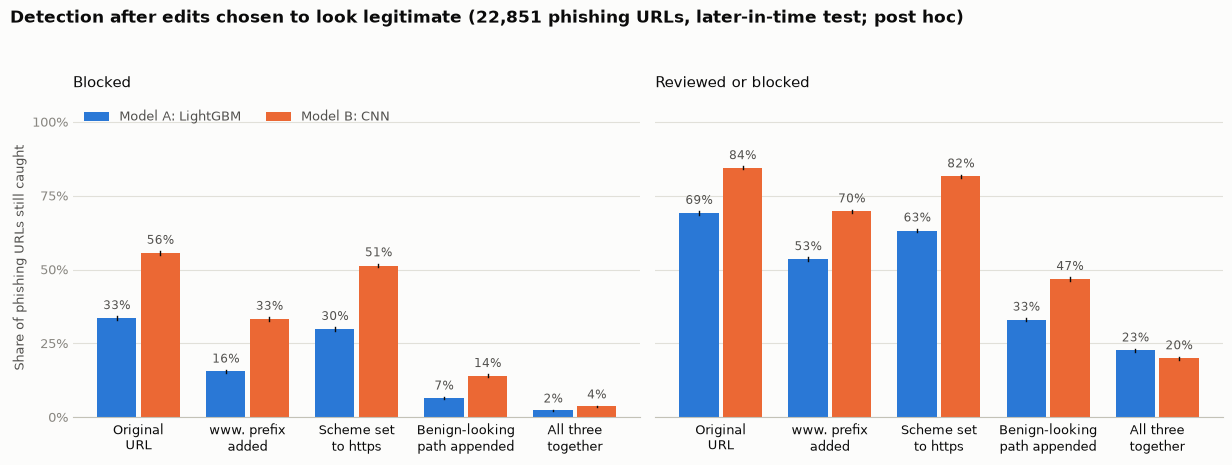

In [14]:
TR = PH["targeted_robustness"]
names = {"www": "www. prefix added", "https": "scheme set to https", "path": "benign-looking path appended",
         "all": "all three together"}
rows = []
point_names = {"block": "blocked", "review": "reviewed or blocked"}
first = {"Edit": "original URL", "URLs the edit changed": "-"}
for n in P.MODELS:
    for p in P.POINTS:
        first[(metrics["scorers"][n]["label"], point_names[p])] = E.fmt(TR["models"][n][p]["before"])
        first[(metrics["scorers"][n]["label"], point_names[p] + ": change")] = "-"
rows.append(first)
for edit, label in names.items():
    row = {"Edit": label, "URLs the edit changed": f"{TR['urls_changed'][edit]:,}"}
    for n in P.MODELS:
        for p in P.POINTS:
            after = TR["models"][n][p]["after"][edit]
            row[(metrics["scorers"][n]["label"], point_names[p])] = E.fmt(after)
            row[(metrics["scorers"][n]["label"], point_names[p] + ": change")] = report.format_change(after["change"])
    rows.append(row)
display(pd.DataFrame(rows).set_index("Edit").T)
P.plot_targeted(TR, E.FIGURES_DIR / "05_targeted_robustness.png");

### 7.1 One appended path at a time

The `path` edit draws one of five paths for each URL. If one path did all the work, the aggregate would hide it.

In [15]:
rows = []
for i, path in enumerate(TR["benign_paths"]):
    row = {"Appended path": path, "URLs": f"{TR['by_benign_path']['lgbm']['block'][i]['urls']:,}"}
    for n in P.MODELS:
        for p in P.POINTS:
            d = TR["by_benign_path"][n][p][i]
            row[f"{metrics['scorers'][n]['label']}, {point_names[p]}"] = f"{d['before']:.1%} to {d['after']:.1%}"
    rows.append(row)
pd.DataFrame(rows).set_index("Appended path")

,URLs,"Model A: LightGBM, blocked","Model A: LightGBM, reviewed or blocked","Model B: character CNN, blocked","Model B: character CNN, reviewed or blocked"
Appended path,,,,,
/about-us,"4,616",33.1% to 19.1%,69.3% to 50.8%,56.3% to 39.4%,84.8% to 69.6%
/en/support/contact,"4,584",33.6% to 4.1%,69.5% to 31.8%,55.5% to 13.9%,84.5% to 64.4%
/blog/2025/03/company-news,"4,618",33.9% to 2.8%,69.2% to 25.4%,55.0% to 2.0%,84.6% to 10.9%
/products/category/item-details.html,"4,592",34.0% to 3.3%,68.8% to 29.5%,55.7% to 3.4%,84.0% to 32.2%
/news/articles/annual-report-2024.html,"4,441",32.8% to 3.3%,68.9% to 27.3%,55.3% to 11.4%,84.4% to 57.2%


## 8. Reference bands for the deployed app

Notebook 04 saved the scores of twenty invented URLs for the app test. Here the same URLs are scored again by the notebook's own path. The raw scores must match the saved ones. The Block, Review or Allow band of each is saved to `reports/app_reference_bands.json`, and a test requires the app to give the same bands.

In [16]:
reference = M.load_json(E.REPORTS_DIR / "app_reference_scores.json")
rows = []
for entry in reference["urls"]:
    frame = pd.DataFrame({"url": [F.normalize_url(entry["url"], strip_query=F.MAIN_STRIP_QUERY)],
                          "url_full": [F.normalize_url(entry["url"])]})
    row = {"url": entry["url"], "main_track_url": frame["url"].iloc[0]}
    for name in P.MODELS:
        score = float(scorers[name]["raw"](frame)[0])
        assert abs(score - entry[name]["raw_score"]) < 1e-6, (entry["url"], name)
        row[name] = {"raw_score": score, "band": str(P.bands([score], **thresholds[name])[0])}
    rows.append(row)
E.write_json({"note": "Invented URLs on reserved example domains. Bands use the frozen block threshold and the post hoc "
                      "review threshold (models/review_operating.json).",
              "decided": P.DECIDED, "urls": rows}, E.REPORTS_DIR / "app_reference_bands.json")
pd.DataFrame([{"url": r["url"][:70], "Model A band": r["lgbm"]["band"], "Model B band": r["cnn"]["band"]} for r in rows])

,url,Model A band,Model B band
0,https://www.example.com,Allow,Allow
1,https://www.example.com/,Allow,Allow
2,example.org/about/team,Allow,Allow
3,https://docs.example.net/guides/getting-started/installation.html,Allow,Allow
4,https://shop.example.com/products/item-48213?ref=newsletter&utm_source,Allow,Allow
5,http://secure-login.account-verify.example.top/signin/,Block,Block
6,http://paypal.com.account-check.example.xyz/verify/login.php?session=8,Block,Block
7,https://xn--pypal-4ve.example/,Review,Review
8,http://192.0.2.44/wp-admin/update/index.html,Block,Block
9,https://storage.example.dev/ipfs/bafybeigdyrztexample/index.html,Allow,Block


## 9. Written results and conclusion

`reports/results.md` is regenerated from `reports/metrics.json`. The tables of the main evaluation are rendered exactly as before; the additions appear under their own heading.

In [17]:
report.write_results_md()
shape = M.load_json(E.REPORTS_DIR / "data_audit.json")["shape_by_class"]["train"]

def pair(value):
    return f"{value('lgbm'):.1%} (Model A) and {value('cnn'):.1%} (Model B)"

ev = RR["phreshphish_eval"]
display(Markdown(
    f"- **The pre-specified warn point was unusable from the start.** On validation it flagged "
    f"{pair(lambda n: warn_val[n]['warn_fpr']['value'])} of legitimate URLs.\n"
    f"- **The review point holds on later data from the same collector.** It catches "
    f"{pair(lambda n: ev[n]['all']['metrics']['review_recall']['value'])} of later phishing, flagging "
    f"{pair(lambda n: ev[n]['all']['metrics']['review_fpr']['value'])} of legitimate URLs. On Wangchuk it flags "
    f"{pair(lambda n: RR['wangchuk'][n]['all']['metrics']['review_fpr']['value'])}.\n"
    f"- **Edits chosen to look legitimate defeat both models.** With all three edits, blocked phishing fell from "
    f"{pair(lambda n: TR['models'][n]['block']['before']['value'])} to "
    f"{pair(lambda n: TR['models'][n]['block']['after']['all']['value'])}. In the training data "
    f"{shape['legitimate']['non_root_path']:.1%} of legitimate URLs have a path and "
    f"{shape['phishing']['bare_homepage']:.1%} of phishing URLs do not, so an appended path reads as benign.\n\n"
    "These are post hoc results. `reports/results.md` gives every interval."
))

- **The pre-specified warn point was unusable from the start.** On validation it flagged 65.9% (Model A) and 71.5% (Model B) of legitimate URLs.
- **The review point holds on later data from the same collector.** It catches 69.1% (Model A) and 84.5% (Model B) of later phishing, flagging 1.1% (Model A) and 1.3% (Model B) of legitimate URLs. On Wangchuk it flags 12.5% (Model A) and 19.0% (Model B).
- **Edits chosen to look legitimate defeat both models.** With all three edits, blocked phishing fell from 33.5% (Model A) and 55.6% (Model B) to 2.3% (Model A) and 3.6% (Model B). In the training data 92.9% of legitimate URLs have a path and 48.4% of phishing URLs do not, so an appended path reads as benign.

These are post hoc results. `reports/results.md` gives every interval.